This notebook was generated using AI under general human direction. At the time of generation, the contents have not been comprehensively reviewed by a human analyst.

# SVM with a polynomial kernel

This notebook uses a support vector classifier (SVC) to predict diabetes from blood pressure alone. It then shows that the polynomial kernel is equivalent to manually adding a squared dimension and fitting a linear classifier.

----

## Setup

### Load packages

`pandas` and `numpy` handle data and numeric work, `matplotlib` and `seaborn` handle plotting, and `scikit-learn` provides the SVC, train/test splitting, scaling, and accuracy.

In [1]:
# load-packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

### Load data

We read the data and look at the first rows to confirm it loaded correctly and to see which columns exist (`bloodpressure`, `glucose`, `diabetes`).

In [2]:
# load-data
df = pd.read_csv("data_diabetes.csv")
df.head()

,glucose,bloodpressure,diabetes
0,40,85,0
1,40,92,0
2,45,63,1
3,45,80,0
4,40,73,1


## Explore the data

### Plot both features

Plotting both features shows how well each separates people with and without diabetes. Color and marker style both encode `diabetes`, and semi-transparent points (`alpha=0.5`) make overlap visible.

<Axes: xlabel='bloodpressure', ylabel='glucose'>

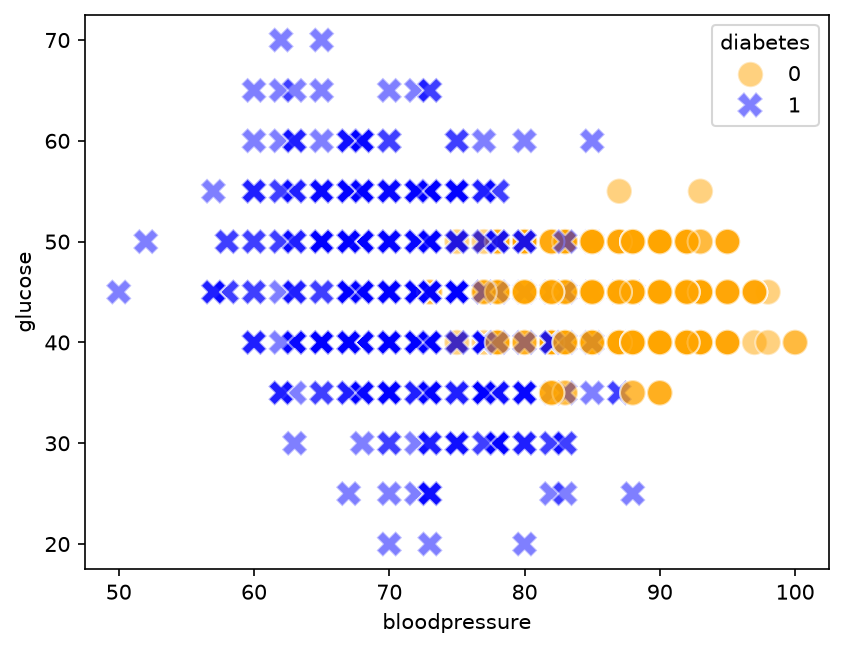

In [3]:
# plot-both-features
sns.scatterplot(df,
        x="bloodpressure",
        y="glucose",
        style=df["diabetes"],
        hue=df["diabetes"],
        s=150,
        alpha=0.5,
        palette=["orange", "blue"])

### Plot blood pressure alone

In order to plot blood pressure alone, we'll set `x="bloodpressure"` and `y=0`. This puts every point on a single number line and shows how well blood pressure by itself separates the two groups. If the groups overlap, a simple threshold would not classify them well, which motivates using an SVM.

<Axes: xlabel='bloodpressure'>

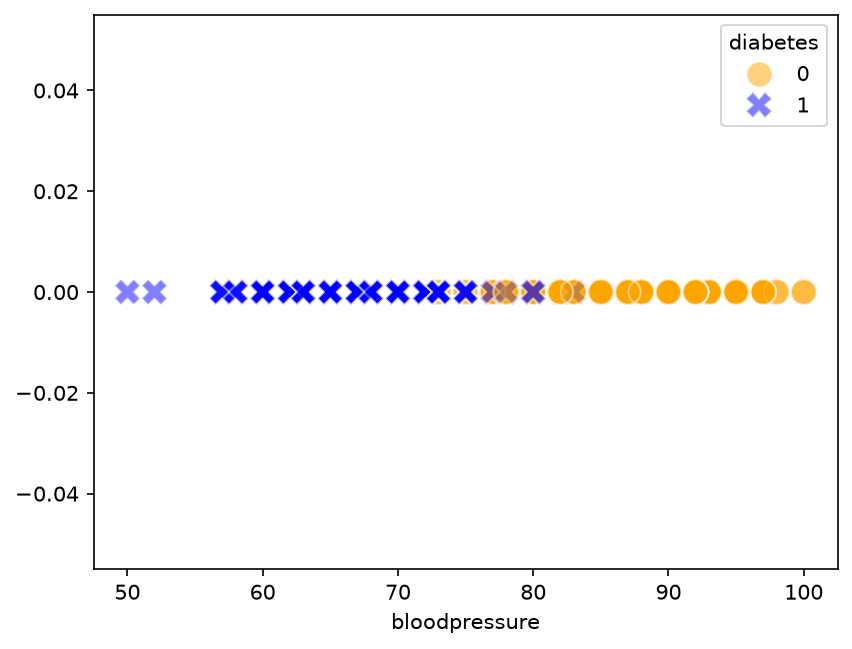

In [4]:
# plot-bloodpressure-only
sns.scatterplot(df,
        x="bloodpressure",
        y=0,
        style=df["diabetes"],
        hue=df["diabetes"],
        s=150,
        alpha=0.5,
        palette=["orange", "blue"])

### Check for missing or non-numeric data

SVMs need numeric input with no missing values. The data types should all be numeric (stray characters would show up as `object` columns), and the null counts should all be zero.

In [5]:
# check-data-quality
print(df.dtypes)
df.isnull().sum()

glucose          int64
bloodpressure    int64
diabetes         int64
dtype: object


glucose          0
bloodpressure    0
diabetes         0
dtype: int64

## Prepare the data

### Define features and target

We will use `bloodpressure` to predict `diabetes`, so we drop `glucose`. Using a single feature keeps the polynomial kernel easy to visualize.

`X` holds the features. `y` is deliberately a 1D Series, because `SVC` expects a 1D target. Using `df[['diabetes']]` would give a DataFrame instead.

In [6]:
# define-features-and-target
X = df.drop(["diabetes", "glucose"], axis=1)
X.head()

,bloodpressure
0,85
1,92
2,63
3,80
4,73


In [8]:
y = df["diabetes"]
y[:5] # print the first 5 values

0    0
1    0
2    1
3    0
4    1
Name: diabetes, dtype: int64

### Split into training and testing sets

We fit the model on 80% of the data and evaluate it on the 20% it has never seen. This gives an honest estimate of performance on new data. `random_state` makes the split reproducible.

In [9]:
# train-test-split
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)

### Standardize the features

SVMs are sensitive to feature scale, so we standardize each feature to have a mean of 0 and a standard deviation of 1 (subtract the mean, divide by the standard deviation).

To avoid data leakage, we calculate the mean and standard deviation from the training data only, then use those values to standardize both the training and testing data:

- `fit_transform()` learns the values from the training data and applies them.
- `transform()` applies the same training values to the test data.

`set_output(transform="pandas")` keeps the results as DataFrames so column names are preserved.

In [10]:
# standardize-features
scaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Plot the scaled test data

We look at the test set on a single axis to see how well blood pressure alone separates the groups. Any remaining overlap means the test data still needs a classifier more flexible than a single threshold.

<Axes: xlabel='bloodpressure'>

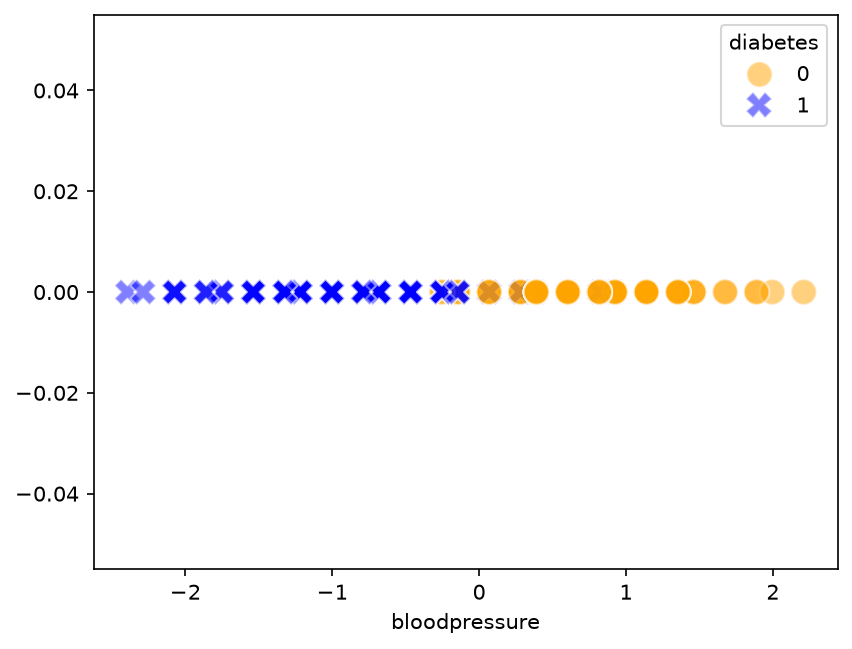

In [11]:
# plot-scaled-test-data
sns.scatterplot(X_test_scaled,
        x="bloodpressure",
        y=0,
        style=y_test,
        hue=y_test,
        s=150,
        alpha=0.5,
        palette=["orange", "blue"])

## Polynomial kernel SVM

### Fit the model

The polynomial kernel lets the SVM find a boundary in a higher-dimensional space without computing that space explicitly. Here `degree=2` and `coef0=0.5` match the parameters from the StatQuest video **[Support Vector Machines Part 2: The Polynomial Kernel](https://youtu.be/Toet3EiSFcM)**.

In [12]:
# fit-poly-model
poly_model = SVC(kernel="poly", degree=2, coef0=0.5)
poly_model.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",2
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.5
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Evaluate the model

We run the test data through the model and build a confusion matrix, which shows the kinds of errors it makes (false positives vs. false negatives). The accuracy score gives a single summary number. Both are computed on the test set only.

In [13]:
# evaluate-poly-model
y_pred = poly_model.predict(X_test_scaled)

poly_confusion_matrix = pd.crosstab(y_test,
                                    y_pred,
                                    rownames=["Actual"],
                                    colnames=["Predicted"])
print(poly_confusion_matrix)

poly_accuracy = accuracy_score(y_pred, y_test)
print(f"Accuracy: {poly_accuracy:.2f}")

Predicted   0   1
Actual           
0          88   5
1          11  95
Accuracy: 0.92


And we see that the model does a pretty good job predicting who has diabetes.

# BAM!

## Visualize the kernel by hand

The polynomial kernel never actually builds the higher-dimensional data. It uses the **kernel trick** to compute relationships between points directly, so there are no transformed coordinates to plot and no classifier line to draw.

To visualize things, we do the transformation ourselves, then fit a *linear* classifier in the new space.

### Add a squared dimension

We copy the scaled data and add a new column, `bloodpressure^2`. This turns the 1D data into 2D data, where the groups can be separated by a straight line. We apply the same transformation to the training and testing data.

In [14]:
# add-squared-dimension
X_linear_train = X_train_scaled.copy()
X_linear_train["bloodpressure^2"] = X_train_scaled ** 2
X_linear_train.head()

,bloodpressure,bloodpressure^2
909,1.139527,1.298521
925,-0.145569,0.021190
974,-0.145569,0.021190
765,-0.681025,0.463795
911,-0.788117,0.621128


In [15]:
X_linear_test = X_test_scaled.copy()
X_linear_test["bloodpressure^2"] = X_test_scaled ** 2
X_linear_test.head()

,bloodpressure,bloodpressure^2
920,-1.002299,1.004604
525,-0.466843,0.217942
567,-1.537756,2.364692
657,1.460801,2.133938
633,0.925344,0.856262


### Fit a linear SVM on the transformed training data

Because the data are already in the higher dimension, the `linear` kernel can find the separating line directly without any further transformation.

In [16]:
# fit-linear-model
linear_model = SVC(kernel="linear")
linear_model.fit(X_linear_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Now run the testing data through the new model

In [17]:
y_pred_linear = linear_model.predict(X_linear_test)

### Compare the two models

If the polynomial kernel is equivalent to the manual transformation plus a linear classifier, the two confusion matrices and the two accuracy scores should match.

In [18]:
# compare-models
linear_confusion_matrix = pd.crosstab(y_test,
                                      y_pred_linear,
                                      rownames=["Actual"],
                                      colnames=["Predicted"])
print(linear_confusion_matrix)
print(poly_confusion_matrix)

linear_accuracy = accuracy_score(y_pred_linear, y_test)
print(f"Linear accuracy: {linear_accuracy:.2f}")
print(f"Polynomial accuracy: {poly_accuracy:.2f}")

Predicted   0   1
Actual           
0          88   5
1          11  95
Predicted   0   1
Actual           
0          88   5
1          11  95
Linear accuracy: 0.92
Polynomial accuracy: 0.92


And we see that both models match.

# DOUBLE BAM!!

## Draw the classifier

### Convert coefficients to a slope and intercept

scikit-learn returns the line as coefficients $w_0$, $w_1$ and $b$ in the equation...

$$w_0 x + w_1 y + b = 0$$

To draw the line we need slope-intercept form. Solving for $y$ gives us...

$$y = -\frac{w_0}{w_1}x - \frac{b}{w_1}$$

...so the slope is $-w_0/w_1$ and the intercept is $-b/w_1$.

In [19]:
# get the coefficients for the classifier
w = linear_model.coef_[0]
b = linear_model.intercept_[0]

# solve for the slope and intercept
slope = -w[0] / w[1]
y_intercept = -b / w[1]
print(slope)
print(y_intercept)

2.600327161481367
-0.07043786916228457


### Plot the transformed test data and the classifier

With blood pressure squared as a second axis, a straight line (red) should separate the two groups. Points on either side of the line are classified accordingly, which is the same classification the polynomial-kernel SVM makes in the original 1D space.

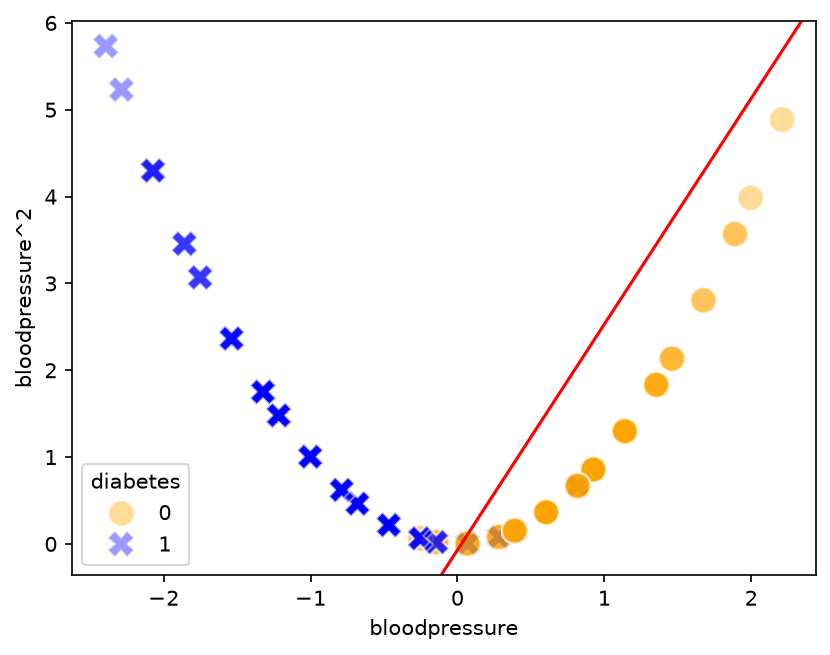

In [20]:
fig, ax = plt.subplots()
sns.scatterplot(data=X_linear_test, 
        x="bloodpressure", 
        y="bloodpressure^2",
        style=y_test,
        hue=y_test,         
        s=150,
        alpha=0.4,
        palette=["orange", "blue"],
        ax=ax)
ax.axline((0, y_intercept), 
            slope=slope, 
            color='red', 
            label='classifier')

# TRIPLE BAM!!!